In [1]:
import re, glob, random, time
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

In [2]:
def load_book(path):
    text = open(path, encoding='utf-8', errors='ignore').read()
    start = re.search(r'\*\*\* START OF .*? \*\*\*', text)
    if start:
        text = text[start.end():]
    end = re.search(r'\*\*\* END OF .*? \*\*\*', text)
    if end:
        text = text[:end.start()]
    return text

files = sorted(glob.glob('*.txt'))
print("Books loaded:", files)

raw_text = ' '.join(load_book(f) for f in files)
print("Characters:", len(raw_text), "| Approx. words:", len(raw_text.split()))

Books loaded: ['Sherlock_holmes.txt']
Characters: 562214 | Approx. words: 104506


In [3]:
def split_sentences(text):
    text = text.replace('’', "'").replace('‘', "'").replace('“', '"').replace('”', '"')
    text = re.sub(r'\b(Mr|Mrs|Ms|Dr|St)\.', r'\1', text)   # don't split sentences at "Mr."
    text = re.sub(r'\s+', ' ', text)
    return re.split(r'(?<=[.!?])\s+', text)

def tokenize(sentence):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", sentence.lower())

raw_sentences = split_sentences(raw_text)
sentences = [tokenize(s) for s in raw_sentences]
sentences = [s for s in sentences if len(s) >= 3]
all_tokens = [w for s in sentences for w in s]

print("Before:", raw_sentences[200])
print("After: ", tokenize(raw_sentences[200]))
print("\nSentences:", len(sentences), "| Tokens:", len(all_tokens), "| Unique words:", len(set(all_tokens)))

Before: With a nod he vanished into the bedroom, whence he emerged in five minutes tweed-suited and respectable, as of old.
After:  ['with', 'a', 'nod', 'he', 'vanished', 'into', 'the', 'bedroom', 'whence', 'he', 'emerged', 'in', 'five', 'minutes', 'tweed', 'suited', 'and', 'respectable', 'as', 'of', 'old']

Sentences: 4610 | Tokens: 105140 | Unique words: 7936


## Preprocessing

Each sentence is lowercased, split into word tokens, and stripped of punctuation and numbers (curly quotes are normalised first so contractions like "don't" survive). I kept sentences separate so that n-grams never run across a sentence boundary.

Stopword removal needs a decision. Removing words like "the", "of" and "and" is useful for finding the meaningful frequent words in the corpus, so I apply it for the word-frequency chart. But it would ruin an autocomplete model, because those are exactly the words people type most. So the n-gram models and the spell checker use the full text with stopwords kept.

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Aarush\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


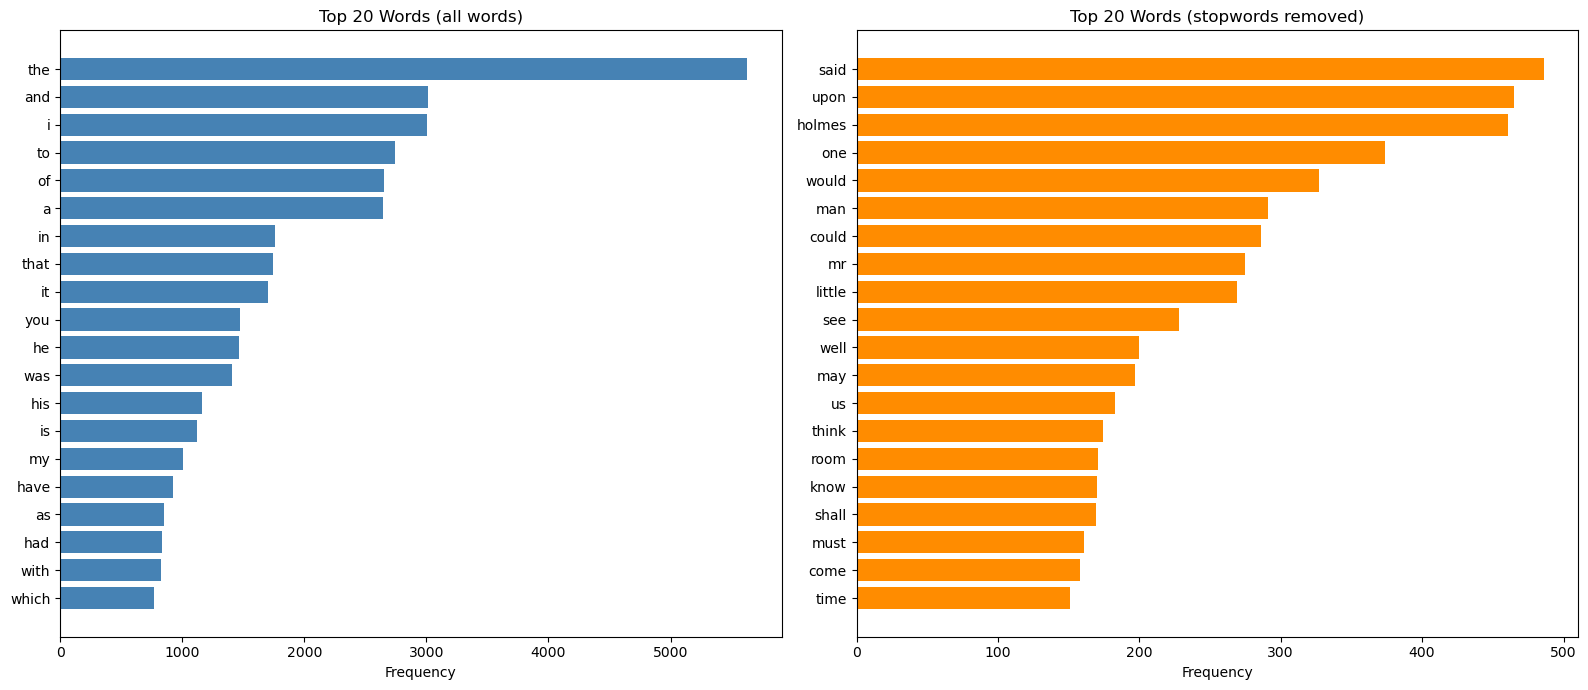

In [4]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

freq_all = Counter(all_tokens)
freq_no_stop = Counter(w for w in all_tokens if w not in stop_words and len(w) > 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, freq, title, color in [(axes[0], freq_all, 'Top 20 Words (all words)', 'steelblue'),
                               (axes[1], freq_no_stop, 'Top 20 Words (stopwords removed)', 'darkorange')]:
    words, counts = zip(*freq.most_common(20))
    ax.barh(words[::-1], counts[::-1], color=color)
    ax.set_title(title)
    ax.set_xlabel('Frequency')
plt.tight_layout()
plt.show()

## Autocomplete with N-gram Models

An n-gram model predicts the next word from the words just before it, using nothing but counts from the training text:
- Bigram: looks at the last 1 word ("my dear" is followed by "fellow" most often, so after "dear" it suggests "fellow").
- Trigram: looks at the last 2 words, which gives more specific predictions. When the pair was never seen in training, it backs off to the bigram model.

I used 80% of the sentences for training and kept 20% hidden to test the models fairly.

In [5]:
rng = random.Random(42)
order = list(range(len(sentences)))
rng.shuffle(order)
cut = int(0.8 * len(order))
train = [sentences[i] for i in order[:cut]]
test = [sentences[i] for i in order[cut:]]
print("Train sentences:", len(train), "| Test sentences:", len(test))

bigram = defaultdict(Counter)
trigram = defaultdict(Counter)
for s in train:
    for i in range(1, len(s)):
        bigram[s[i-1]][s[i]] += 1
    for i in range(2, len(s)):
        trigram[(s[i-2], s[i-1])][s[i]] += 1

print("Bigram contexts:", len(bigram), "| Trigram contexts:", len(trigram))

Train sentences: 3688 | Test sentences: 922
Bigram contexts: 6839 | Trigram contexts: 38379


In [6]:
def predict_bigram(prefix, k=3):
    words = tokenize(prefix)
    if not words:
        return []
    nxt = bigram.get(words[-1])
    return [w for w, _ in nxt.most_common(k)] if nxt else []

def predict_trigram(prefix, k=3):
    words = tokenize(prefix)
    out = []
    if len(words) >= 2:
        nxt = trigram.get((words[-2], words[-1]))
        if nxt:
            out = [w for w, _ in nxt.most_common(k)]
    if len(out) < k:                       # back off to the bigram model
        for w in predict_bigram(prefix, k + len(out)):
            if w not in out:
                out.append(w)
            if len(out) == k:
                break
    return out

prefixes = ['sherlock', 'i am', 'it was a', 'the man', 'my dear', 'what do you', 'he said',
            'in the', 'i have', 'there was', 'mr holmes', 'baker street', 'upon the', 'i think that']

demo = pd.DataFrame({
    'Prefix': prefixes,
    'Bigram top 3': [', '.join(predict_bigram(p)) for p in prefixes],
    'Trigram top 3': [', '.join(predict_trigram(p)) for p in prefixes]
})
demo

,Prefix,Bigram top 3,Trigram top 3
0,sherlock,holmes,holmes
1,i am,"sure, not, afraid","sure, not, afraid"
2,it was a,"very, little, man","very, man, small"
3,the man,"who, with, and","who, sat, of"
4,my dear,"fellow, young, little","fellow, young, holmes"
5,what do you,"have, are, will","think, know, not"
6,he said,"he, holmes, i","that, at, a"
7,in the,"door, other, matter","morning, matter, world"
8,i have,"been, a, no","no, been, heard"
9,there was,"a, the, not","a, no, the"


## Autocomplete Metrics

I tested on the held-out sentences: at every position the model sees the words so far and must predict the next word. A prediction counts as a hit if the real next word is among the top-k suggestions.
- Coverage = share of test cases where the model could make any suggestion at all.
- Precision = hits / cases where it made a suggestion (when it speaks, how often is it right?).
- Recall = hits / all test cases (out of everything the user could type, how often did it have the right word?).
- F1 combines precision and recall.

In [7]:
def evaluate_autocomplete(predict, k):
    total = answered = hits = 0
    for s in test:
        for i in range(2, len(s)):
            prefix, target = ' '.join(s[:i]), s[i]
            total += 1
            preds = predict(prefix, k)
            if preds:
                answered += 1
                if target in preds:
                    hits += 1
    precision = hits / answered if answered else 0
    recall = hits / total
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
    return {'Test cases': total, 'Coverage': answered / total,
            'Precision': precision, 'Recall': recall, 'F1': f1}

rows = []
for name, fn in [('Bigram', predict_bigram), ('Trigram + backoff', predict_trigram)]:
    for k in (1, 3):
        r = evaluate_autocomplete(fn, k)
        r.update({'Model': name, 'Top-k': k})
        rows.append(r)

ac_results = pd.DataFrame(rows)[['Model', 'Top-k', 'Test cases', 'Coverage', 'Precision', 'Recall', 'F1']].round(3)
ac_results

,Model,Top-k,Test cases,Coverage,Precision,Recall,F1
0,Bigram,1,19738,0.96,0.139,0.133,0.136
1,Bigram,3,19738,0.96,0.247,0.237,0.242
2,Trigram + backoff,1,19738,0.96,0.148,0.142,0.145
3,Trigram + backoff,3,19738,0.96,0.255,0.245,0.250


In [8]:
pip install pyspellchecker


     ---------------------------------------- 7.2/7.2 MB 603.0 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [9]:
from spellchecker import SpellChecker
spell = SpellChecker()

# vocabulary and word counts from the corpus (used by the custom corrector)
vocab_counts = Counter(w for w in all_tokens if "'" not in w)
vocab = list(vocab_counts)

def levenshtein(a, b):
    """Minimum number of single-letter edits (insert, delete, replace) to turn a into b."""
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j-1] + 1, prev[j-1] + (ca != cb)))
        prev = cur
    return prev[-1]

def correct_pyspell(word):
    c = spell.correction(word)
    return c if c else word

def correct_custom(word):
    """Pick the corpus word with the smallest edit distance (max 2); break ties by corpus frequency."""
    if word in vocab_counts:
        return word
    best, best_key = word, None
    for v in vocab:
        if abs(len(v) - len(word)) > 2:
            continue
        d = levenshtein(word, v)
        if d > 2:
            continue
        key = (d, -vocab_counts[v])
        if best_key is None or key < best_key:
            best, best_key = v, key
    return best

## Autocorrect Test Design and Metrics

I tested both correctors on 30 deliberately misspelled words (missing, extra, swapped and wrong letters) plus 30 correctly spelled words, including character names like holmes and watson, to check that the corrector doesn't damage words that are already right.
- Correction accuracy = misspelled words fixed to the intended word / 30.
- Precision = correct fixes / all words the corrector changed (including any correct words it changed by mistake).
- Recall = correct fixes / 30 misspelled words.
- Confusion matrix: each word's status before autocorrect (correct or misspelled) against its status after (correct or incorrect).

In [10]:
misspelled = [('detectve','detective'), ('adventre','adventure'), ('inspecter','inspector'), ('gentelman','gentleman'),
              ('mystry','mystery'), ('beleive','believe'), ('recieve','receive'), ('wich','which'), ('thier','their'),
              ('seperate','separate'), ('necesary','necessary'), ('occured','occurred'), ('untill','until'),
              ('definately','definitely'), ('wierd','weird'), ('knowlege','knowledge'), ('freind','friend'),
              ('anwser','answer'), ('tomorow','tomorrow'), ('becuase','because'), ('murdr','murder'),
              ('windw','window'), ('strret','street'), ('evidance','evidence'), ('suspicous','suspicious'),
              ('carrage','carriage'), ('mornning','morning'), ('evning','evening'), ('lettter','letter'), ('rooom','room')]

correct_words = ['street', 'window', 'letter', 'morning', 'evening', 'gentleman', 'detective', 'murder', 'carriage',
                 'mystery', 'evidence', 'knowledge', 'friend', 'answer', 'because', 'which', 'their', 'until',
                 'believe', 'receive', 'separate', 'necessary', 'suspicious', 'adventure', 'inspector',
                 'holmes', 'watson', 'lestrade', 'baker', 'adler']

methods = {'pyspellchecker': correct_pyspell, 'Custom Levenshtein': correct_custom}
details = pd.DataFrame({'Misspelled': [m for m, c in misspelled], 'Intended': [c for m, c in misspelled]})
summary, cms = [], {}

for name, fn in methods.items():
    start = time.time()
    mis_out = [fn(m) for m, c in misspelled]
    cor_out = [fn(w) for w in correct_words]
    seconds = time.time() - start

    fixed = sum(o == c for o, (m, c) in zip(mis_out, misspelled))
    kept = sum(o == w for o, w in zip(cor_out, correct_words))
    changed = sum(o != m for o, (m, c) in zip(mis_out, misspelled)) + sum(o != w for o, w in zip(cor_out, correct_words))

    precision = fixed / changed if changed else 0
    recall = fixed / len(misspelled)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

    details[name] = [('OK  ' if o == c else 'WRONG ') + o for o, (m, c) in zip(mis_out, misspelled)]
    cms[name] = [[kept, len(correct_words) - kept], [fixed, len(misspelled) - fixed]]
    summary.append({'Method': name, 'Fixed': f"{fixed}/{len(misspelled)}", 'Correction accuracy': fixed / len(misspelled),
                    'Correct words kept': f"{kept}/{len(correct_words)}", 'Precision': precision,
                    'Recall': recall, 'F1': f1, 'Time (sec)': seconds})

details

,Misspelled,Intended,pyspellchecker,Custom Levenshtein
0,detectve,detective,OK detective,OK detective
1,adventre,adventure,OK adventure,OK adventure
2,inspecter,inspector,OK inspector,OK inspector
3,gentelman,gentleman,OK gentleman,OK gentleman
4,mystry,mystery,OK mystery,OK mystery
5,beleive,believe,OK believe,OK believe
6,recieve,receive,OK receive,WRONG relieve
7,wich,which,WRONG with,WRONG with
8,thier,their,OK their,WRONG thief
9,seperate,separate,OK separate,OK separate


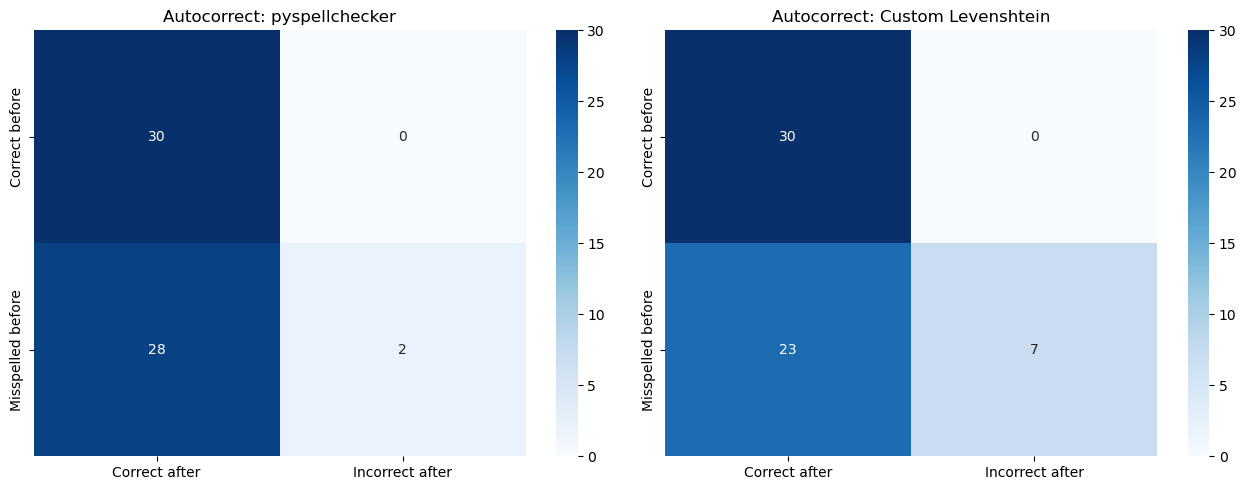

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, cm) in zip(axes, cms.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Correct after', 'Incorrect after'],
                yticklabels=['Correct before', 'Misspelled before'])
    ax.set_title(f'Autocorrect: {name}')
plt.tight_layout()
plt.show()

## Discussion: Limitations vs Production Systems like Google Keyboard

Results summary: the trigram model with backoff was slightly better than the bigram model (about 25.5% against 24.7% of the true next words appearing in the top 3), but the gain is small because the training text is small, so most two-word contexts have only been seen a few times. For autocorrect, pyspellchecker fixed 28 of 30 misspellings against 23 for my custom Levenshtein corrector, and it was far faster, while neither changed any correctly spelled word.

Where my implementation falls short of a production keyboard:
- Data: my corpus is about 105,000 words from one Victorian detective novel, so the predictions sound like Sherlock Holmes and my custom corrector can only fix words that appear in the book (it left "tomorow" alone because "tomorrow" is not in the text). Production systems learn from billions of words of modern, varied text.
- Context: my models look at only the last 1 or 2 words. Production keyboards use neural language models that read the whole sentence, so they can tell "he said that" from "he said hello".
- Spelling errors: my correctors only fix non-words using edit distance, and they ignore context. They can't catch real-word errors ("form" typed instead of "from"), and Levenshtein counts a swapped pair of letters as two edits, which is why it turned "thier" into "thief" and "freind" into "find". Production systems also model which keys sit next to each other on the keyboard and use the sentence context to choose between candidates.
- Personalisation and language: real keyboards learn your own names, slang and emoji habits on the device, and handle many languages and mixed-language typing.
- Engineering: speed and memory matter on a phone. My custom corrector compares each word against the whole vocabulary and took over 2 seconds for 60 words, which would be far too slow without indexing or smarter search.